In [2]:
from google.colab import files

files.upload()  # Выбери colab_data.zip

!unzip -q /content/colab_data.zip -d /content/dbm

%cd /content/dbm

Saving colab_data.zip to colab_data.zip
/content/dbm


# Глубокая гибридная CNN для обратной задачи DBM

Модель объединяет глубокий residual-энкодер маски и полносвязную ветвь морфологии.
Все части модели обучаются совместно с нуля; старый checkpoint CNN не требуется.

Подготовка: групповой train/validation split по point_id, проверка разделения disorder_seed,
заполнение пропусков и нормализация исключительно по train. Отражения масок отключены.

Этот ноутбук содержит подготовку данных, архитектуру и проверку формы выхода.
Цикл обучения и оценку качества добавим следующими ячейками.

Запускай из корня проекта или notebooks. Нужны data/ml_dataset/dataset_inverse.csv
и соответствующие NPZ-маски с ключом channel.


In [6]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")

PyTorch: 2.14.1+cu130
Device: cpu


In [7]:
import sys

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src" / "morphology_features.py").is_file()),
    None,
)
assert PROJECT_ROOT is not None, "Открой ноутбук из папки проекта"

sys.path.insert(0, str(PROJECT_ROOT))
from src.morphology_features import MORPHOLOGY_FEATURES
FEATURE_COLUMNS = list(MORPHOLOGY_FEATURES)

DATA_DIR = PROJECT_ROOT / "data" / "ml_dataset"
DATA_FILE = DATA_DIR / "dataset_inverse.csv"
RESULTS_DIR = PROJECT_ROOT / "results" / "deep_hybrid_inverse"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_FILE.is_file(), f"Не найден датасет: {DATA_FILE}"
print("Корень проекта:", PROJECT_ROOT)
print("Количество признаков:", len(FEATURE_COLUMNS))
print("Датасет:", DATA_FILE)
print("Результаты:", RESULTS_DIR)


Корень проекта: /home/artur/PycharmProjects/Mathprac
Количество признаков: 27
Датасет: /home/artur/PycharmProjects/Mathprac/data/ml_dataset/dataset_inverse.csv
Результаты: /home/artur/PycharmProjects/Mathprac/results/deep_hybrid_inverse


In [8]:
TARGET_COLUMNS = [
    "eta",
    "mean_breakdown_field",
    "correlation_length",
    "weibull_shape",
]

dataset = pd.read_csv(
    DATA_FILE,
    dtype={
        "disorder_seed": "uint64",
        "random_seed": "uint64",
    },
)

required_columns = {
    "run_id",
    "point_id",
    "disorder_seed",
    "split",
    "image_path",
    *TARGET_COLUMNS,
    *FEATURE_COLUMNS,
}

missing_columns = required_columns - set(dataset.columns)

assert not missing_columns, (
    f"В датасете отсутствуют столбцы: {sorted(missing_columns)}"
)

assert dataset["run_id"].notna().all(), "Есть пустые run_id"
assert dataset["run_id"].is_unique, "Есть повторяющиеся run_id"

assert dataset[TARGET_COLUMNS].notna().all().all(), (
    "Есть пропуски в целевых параметрах"
)

print("Количество примеров:", len(dataset))
print("Количество столбцов:", dataset.shape[1])

display(
    dataset[
        ["run_id", "point_id", "split", *TARGET_COLUMNS]
    ].head()
)

Количество примеров: 10199
Количество столбцов: 45


,run_id,point_id,split,eta,mean_breakdown_field,correlation_length,weibull_shape
0,global-000003-m0-g0,global-000003,train,1.188938,2.922237,2,14.289726
1,global-000007-m0-g0,global-000007,train,0.787852,2.743639,14,2.879581
2,global-000008-m0-g0,global-000008,train,0.509025,3.220241,4,6.943663
3,global-000009-m0-g0,global-000009,train,1.839728,2.881764,15,13.146752
4,global-000010-m0-g0,global-000010,train,2.930976,3.090365,4,2.767735


In [9]:
from sklearn.model_selection import GroupShuffleSplit

train_pool = dataset.loc[
    dataset["split"] == "train"
].copy()

assert not train_pool.empty, "Исходный train пуст"
assert train_pool["point_id"].notna().all(), "Есть пустые point_id"

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED,
)

train_indices, validation_indices = next(
    group_split.split(
        train_pool,
        groups=train_pool["point_id"],
    )
)

train_data = train_pool.iloc[
    train_indices
].reset_index(drop=True)

validation_data = train_pool.iloc[
    validation_indices
].reset_index(drop=True)

train_points = set(train_data["point_id"])
validation_points = set(validation_data["point_id"])

assert train_points.isdisjoint(validation_points), (
    "Есть общие point_id между train и validation"
)

train_seeds = set(train_data["disorder_seed"])
validation_seeds = set(validation_data["disorder_seed"])

assert train_seeds.isdisjoint(validation_seeds), (
    "Есть общие карты неоднородности между train и validation"
)

print("Train:", len(train_data))
print("Validation:", len(validation_data))
print("Точек параметров в train:", len(train_points))
print("Точек параметров в validation:", len(validation_points))

Train: 6560
Validation: 1706
Точек параметров в train: 4764
Точек параметров в validation: 1192


In [18]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

assert np.isfinite(train_data[TARGET_COLUMNS].to_numpy()).all()
assert np.isfinite(validation_data[TARGET_COLUMNS].to_numpy()).all()

target_mean = train_data[TARGET_COLUMNS].mean()
target_std = train_data[TARGET_COLUMNS].std(ddof=0)
assert (target_std > 0).all(), "Есть цель без вариации в train"

y_train = (
    (train_data[TARGET_COLUMNS] - target_mean) / target_std
).to_numpy(dtype=np.float32)
y_validation = (
    (validation_data[TARGET_COLUMNS] - target_mean) / target_std
).to_numpy(dtype=np.float32)

features_train = train_data[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
features_validation = validation_data[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
assert features_train.notna().any().all(), "Есть полностью пустой признак в train"

feature_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
X_train = feature_preprocessor.fit_transform(features_train).astype(np.float32)
X_validation = feature_preprocessor.transform(features_validation).astype(np.float32)
assert np.isfinite(X_train).all()
assert np.isfinite(X_validation).all()

print("Признаки:", X_train.shape, X_validation.shape)
print("Цели:", y_train.shape, y_validation.shape)

Признаки: (6560, 27) (1706, 27)
Цели: (6560, 4) (1706, 4)


In [16]:
class DBMHybridDataset(Dataset):
    def __init__(self, frame, features, targets, data_dir):
        self.frame = frame.reset_index(drop=True).copy()
        self.data_dir = Path(data_dir)

        assert len(self.frame) == len(features) == len(targets)

        assert features.shape == (
            len(self.frame),
            len(FEATURE_COLUMNS),
        )

        assert targets.shape == (
            len(self.frame),
            len(TARGET_COLUMNS),
        )

        assert self.frame["image_path"].notna().all()

        self.features = torch.from_numpy(
            np.ascontiguousarray(features, dtype=np.float32)
        )

        self.targets = torch.from_numpy(
            np.ascontiguousarray(targets, dtype=np.float32)
        )

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        image_file = (
            self.data_dir
            / self.frame.iloc[index]["image_path"]
        )

        with np.load(image_file, allow_pickle=False) as saved:
            mask = saved["channel"].astype(np.float32)

        assert mask.shape == (128, 128), (
            f"Неверный размер маски: {image_file}"
        )

        assert np.isin(mask, [0.0, 1.0]).all(), (
            f"Маска не бинарная: {image_file}"
        )

        mask = torch.from_numpy(mask).unsqueeze(0)
        features = self.features[index]
        targets = self.targets[index]

        return mask, features, targets

In [17]:
train_dataset = DBMHybridDataset(
    frame=train_data, features=X_train, targets=y_train, data_dir=DATA_DIR,
)
validation_dataset = DBMHybridDataset(
    frame=validation_data, features=X_validation,
    targets=y_validation, data_dir=DATA_DIR,
)

BATCH_SIZE = 32
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"
data_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    generator=data_generator,
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
print("Примеров train:", len(train_dataset))
print("Примеров validation:", len(validation_dataset))

NameError: name 'X_train' is not defined

In [14]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU()

        if in_channels == out_channels:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    bias=False,
                ),
                nn.BatchNorm2d(out_channels),
            )

    def forward(self, x):
        identity = self.shortcut(x)

        output = self.conv1(x)
        output = self.bn1(output)
        output = self.relu(output)

        output = self.conv2(output)
        output = self.bn2(output)

        output = output + identity
        output = self.relu(output)

        return output

## Архитектура гибридной модели

### Ветвь изображения

Вход — бинарная маска `[B, 1, 128, 128]`,
где B — размер батча.

На каждом уровне выполняются два residual-блока,
затем MaxPool 2 × 2:

| Уровень | Выходная форма |
|---|---|
| Первый | `[B, 16, 64, 64]` |
| Второй | `[B, 32, 32, 32]` |
| Третий | `[B, 64, 16, 16]` |
| Четвёртый | `[B, 128, 8, 8]` |

Каждый residual-блок содержит две свёртки 3 × 3,
BatchNorm и ReLU. Обходная связь добавляет вход
к результату обработки. При изменении числа каналов
в обходном пути используется свёртка 1 × 1.

Всего — восемь residual-блоков и 16 основных свёрток 3 × 3.
Дополнительные блоки обрабатывают признаки до уменьшения
пространственного разрешения.

### Представление маски

Average и maximum adaptive pooling преобразуют карты
в две сетки 4 × 4. После разворачивания и объединения
получаем 4096 чисел.

Полносвязная ветвь: **4096 → 256 → 128**.
Используются ReLU и Dropout 0.25.

### Ветвь морфологии

Нормализованные признаки проходят через полносвязную ветвь:

**27 → 64 → 32**, с ReLU после каждого слоя.

Морфология предоставляет явные характеристики той же маски,
а не независимые данные.

### Объединение и предсказание

Соединяем представления: **128 + 32 = 160 признаков**.

Регрессионная голова: **160 → 64 → 4**.
После промежуточного слоя — ReLU и Dropout 0.20.

Выход — нормализованные параметры.
Последний слой без активации, поскольку параметры
после нормализации могут принимать отрицательные значения.

Все ветви обучаются совместно. При оценке Dropout выключен,
а BatchNorm использует накопленные статистики.

In [13]:
class DBMDeepHybridCNN(nn.Module):
    def __init__(self, number_of_features, number_of_targets=4):
        super().__init__()

        self.encoder = nn.Sequential(
            ResidualBlock(1, 16),
            ResidualBlock(16, 16),
            nn.MaxPool2d(2),

            ResidualBlock(16, 32),
            ResidualBlock(32, 32),
            nn.MaxPool2d(2),

            ResidualBlock(32, 64),
            ResidualBlock(64, 64),
            nn.MaxPool2d(2),

            ResidualBlock(64, 128),
            ResidualBlock(128, 128),
            nn.MaxPool2d(2),
        )

        self.average_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.maximum_pool = nn.AdaptiveMaxPool2d((4, 4))

        self.image_branch = nn.Sequential(
            nn.Linear(4096, 256),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(256, 128),
            nn.ReLU(),
        )

        self.morphology_branch = nn.Sequential(
            nn.Linear(number_of_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
        )

        self.regression_head = nn.Sequential(
            nn.Linear(128 + 32, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, number_of_targets),
        )

    def forward(self, masks, morphology):
        feature_maps = self.encoder(masks)

        average_features = self.average_pool(
            feature_maps
        ).flatten(1)

        maximum_features = self.maximum_pool(
            feature_maps
        ).flatten(1)

        pooled_features = torch.cat(
            [average_features, maximum_features],
            dim=1,
        )

        image_embedding = self.image_branch(pooled_features)
        morphology_embedding = self.morphology_branch(morphology)

        combined_features = torch.cat(
            [image_embedding, morphology_embedding],
            dim=1,
        )

        predictions = self.regression_head(combined_features)

        return predictions

In [11]:
batch_masks, batch_features, batch_targets = next(
    iter(validation_loader)
)
model = DBMDeepHybridCNN(
    number_of_features=len(FEATURE_COLUMNS),
    number_of_targets=len(TARGET_COLUMNS),
).to(DEVICE)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

model.eval()

with torch.no_grad():
    sample_predictions = model(
        batch_masks.to(DEVICE),
        batch_features.to(DEVICE),
    )

assert sample_predictions.shape == batch_targets.shape, (
    f"Выход: {sample_predictions.shape}, "
    f"цели: {batch_targets.shape}"
)

assert torch.isfinite(sample_predictions).all(), (
    "Предсказания содержат NaN или бесконечности"
)

model.train()

print("Устройство:", DEVICE)
print(f"Всего параметров: {total_parameters:,}")
print(f"Обучаемых параметров: {trainable_parameters:,}")
print("Размер выхода:", sample_predictions.shape)
print("Пример выхода:", sample_predictions[0].detach().cpu())

Устройство: cuda
Всего параметров: 1,793,764
Обучаемых параметров: 1,793,764
Размер выхода: torch.Size([32, 4])
Пример выхода: tensor([-0.1137,  0.1231,  0.0202,  0.0374])


In [12]:
criterion = nn.SmoothL1Loss(beta=1.0)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
)

In [13]:
from tqdm.notebook import tqdm


def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    progress=None,
):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    total_examples = 0

    for masks, features, targets in loader:
        masks = masks.to(DEVICE, non_blocking=PIN_MEMORY)
        features = features.to(DEVICE, non_blocking=PIN_MEMORY)
        targets = targets.to(DEVICE, non_blocking=PIN_MEMORY)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            predictions = model(masks, features)
            loss = criterion(predictions, targets)

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

        if progress is not None:
            progress.set_postfix(
                loss=f"{total_loss / total_examples:.5f}",
                refresh=False,
            )
            progress.update(1)

    if total_examples == 0:
        raise ValueError("Загрузчик не содержит примеров")

    return total_loss / total_examples

In [14]:
import time
import joblib

MAX_EPOCHS = 70
EARLY_STOPPING_PATIENCE = 15

BEST_MODEL_FILE = RESULTS_DIR / "best_deep_hybrid.pt"

joblib.dump(
    feature_preprocessor,
    RESULTS_DIR / "feature_preprocessor.joblib",
)

history = []
best_validation_loss = np.inf
epochs_without_improvement = 0

batches_per_epoch = len(train_loader) + len(validation_loader)

with tqdm(
    total=batches_per_epoch,
    desc="Epoch 1",
    unit="batch",
    colour="green",
    mininterval=0.2,
    leave=True,
) as progress:

    for epoch in range(1, MAX_EPOCHS + 1):
        progress.reset(total=batches_per_epoch)
        progress.set_postfix(refresh=False)
        progress.set_description(
            f"Epoch {epoch}/{MAX_EPOCHS} · Train"
        )

        epoch_start = time.perf_counter()

        train_loss = run_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            progress=progress,
        )

        progress.set_description(
            f"Epoch {epoch}/{MAX_EPOCHS} · Validation"
        )

        validation_loss = run_epoch(
            model=model,
            loader=validation_loader,
            criterion=criterion,
            progress=progress,
        )

        if not np.isfinite([train_loss, validation_loss]).all():
            raise RuntimeError("Получен NaN или бесконечный loss")

        scheduler.step(validation_loss)

        learning_rate = optimizer.param_groups[0]["lr"]
        elapsed = time.perf_counter() - epoch_start

        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "learning_rate": learning_rate,
                "seconds": elapsed,
            }
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            epochs_without_improvement = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "validation_loss": validation_loss,
                    "target_columns": TARGET_COLUMNS,
                    "feature_columns": FEATURE_COLUMNS,
                    "target_mean": target_mean.to_dict(),
                    "target_std": target_std.to_dict(),
                    "model_config": {
                        "number_of_features": len(FEATURE_COLUMNS),
                        "number_of_targets": len(TARGET_COLUMNS),
                    },
                    "seed": SEED,
                },
                BEST_MODEL_FILE,
            )
        else:
            epochs_without_improvement += 1

        pd.DataFrame(history).to_csv(
            RESULTS_DIR / "training_history.csv",
            index=False,
        )

        progress.set_description(
            f"Epoch {epoch}/{MAX_EPOCHS} · Done"
        )
        progress.set_postfix(
            train=f"{train_loss:.5f}",
            validation=f"{validation_loss:.5f}",
        )

        print(
            f"Epoch {epoch:02d} | "
            f"train: {train_loss:.5f} | "
            f"validation: {validation_loss:.5f} | "
            f"lr: {learning_rate:.2e} | "
            f"time: {elapsed:.1f}s"
        )

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("Early stopping")
            break

print(f"Лучший validation loss: {best_validation_loss:.5f}")
print("Лучшие веса:", BEST_MODEL_FILE)

Epoch 1:   0%|          | 0/259 [00:00<?, ?batch/s]

Epoch 01 | train: 0.35435 | validation: 0.31606 | lr: 1.00e-03 | time: 22.3s
Epoch 02 | train: 0.30923 | validation: 0.30079 | lr: 1.00e-03 | time: 22.1s
Epoch 03 | train: 0.29965 | validation: 0.29406 | lr: 1.00e-03 | time: 21.5s
Epoch 04 | train: 0.29259 | validation: 0.29633 | lr: 1.00e-03 | time: 22.3s
Epoch 05 | train: 0.28753 | validation: 0.29251 | lr: 1.00e-03 | time: 22.2s
Epoch 06 | train: 0.28402 | validation: 0.28762 | lr: 1.00e-03 | time: 22.1s
Epoch 07 | train: 0.27853 | validation: 0.27814 | lr: 1.00e-03 | time: 21.9s
Epoch 08 | train: 0.27436 | validation: 0.27773 | lr: 1.00e-03 | time: 22.2s
Epoch 09 | train: 0.26896 | validation: 0.27965 | lr: 1.00e-03 | time: 21.9s
Epoch 10 | train: 0.26649 | validation: 0.27443 | lr: 1.00e-03 | time: 22.1s
Epoch 11 | train: 0.26188 | validation: 0.28633 | lr: 1.00e-03 | time: 22.0s
Epoch 12 | train: 0.25991 | validation: 0.26956 | lr: 1.00e-03 | time: 22.3s
Epoch 13 | train: 0.25445 | validation: 0.27358 | lr: 1.00e-03 | time: 21.9s

In [15]:
from tqdm.notebook import tqdm
from sklearn.metrics import mean_absolute_error, r2_score
from IPython.display import display

checkpoint = torch.load(
    BEST_MODEL_FILE,
    map_location="cpu",
    weights_only=False,
)

columns = list(checkpoint["target_columns"])
assert columns == list(TARGET_COLUMNS)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Лучшая эпоха:", checkpoint["epoch"])
print(f"Validation loss: {checkpoint['validation_loss']:.5f}")

predictions_batches = []
targets_batches = []

with torch.inference_mode():
    for masks, features, targets in tqdm(
        validation_loader,
        desc="Проверка модели",
        unit="batch",
        colour="green",
    ):
        masks = masks.to(DEVICE)
        features = features.to(DEVICE)

        predictions = model(masks, features)

        predictions_batches.append(predictions.cpu().numpy())
        targets_batches.append(targets.cpu().numpy())

predictions_normalized = np.concatenate(predictions_batches, axis=0)
targets_normalized = np.concatenate(targets_batches, axis=0)

means = np.array([checkpoint["target_mean"][c] for c in columns])
stds = np.array([checkpoint["target_std"][c] for c in columns])

validation_predictions = predictions_normalized * stds + means
validation_targets = targets_normalized * stds + means

assert np.isfinite(validation_predictions).all()

metrics_rows = []

for index, column in enumerate(columns):
    actual = validation_targets[:, index]
    predicted = validation_predictions[:, index]

    metrics_rows.append(
        {
            "parameter": column,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(np.mean((actual - predicted) ** 2)),
            "R2": r2_score(actual, predicted),
            "RMSE_mean_baseline": np.sqrt(
                np.mean((actual - means[index]) ** 2)
            ),
        }
    )

validation_metrics = pd.DataFrame(metrics_rows)
display(validation_metrics.round(4))

validation_metrics.to_csv(
    RESULTS_DIR / "validation_metrics.csv",
    index=False,
)

Лучшая эпоха: 15
Validation loss: 0.26912


Проверка модели:   0%|          | 0/54 [00:00<?, ?batch/s]

,parameter,MAE,RMSE,R2,RMSE_mean_baseline
0,eta,0.2546,0.3533,0.7799,0.7540
1,mean_breakdown_field,0.1338,0.1623,0.0692,0.1683
2,correlation_length,2.8854,3.6520,0.3227,4.4382
3,weibull_shape,2.1533,2.7285,0.5012,3.8715


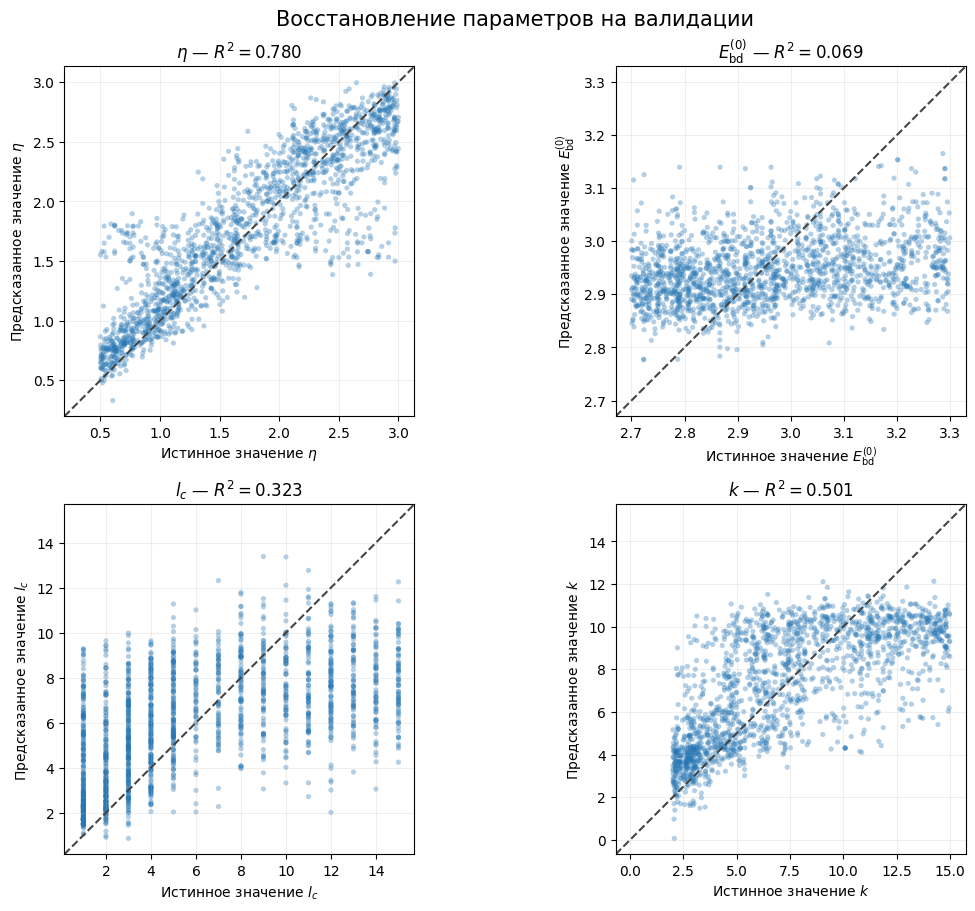

In [16]:
import matplotlib.pyplot as plt

parameter_labels = {
    "eta": r"$\eta$",
    "mean_breakdown_field": r"$E_{\mathrm{bd}}^{(0)}$",
    "correlation_length": r"$l_c$",
    "weibull_shape": r"$k$",
}

with plt.style.context("default"):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(11, 9),
        constrained_layout=True,
        facecolor="white",
    )

    for index, ax in enumerate(axes.flat):
        column = columns[index]
        label = parameter_labels[column]

        actual = validation_targets[:, index]
        predicted = validation_predictions[:, index]

        ax.scatter(
            actual,
            predicted,
            s=14,
            alpha=0.35,
            color="#2878B5",
            edgecolors="none",
        )

        lower = min(actual.min(), predicted.min())
        upper = max(actual.max(), predicted.max())
        margin = 0.05 * max(upper - lower, 1e-8)
        limits = (lower - margin, upper + margin)

        ax.plot(
            limits,
            limits,
            linestyle="--",
            color="#444444",
            linewidth=1.5,
        )

        ax.set_xlim(limits)
        ax.set_ylim(limits)
        ax.set_aspect("equal", adjustable="box")

        score = r2_score(actual, predicted)
        ax.set_title(f"{label} — $R^2 = {score:.3f}$")
        ax.set_xlabel(f"Истинное значение {label}")
        ax.set_ylabel(f"Предсказанное значение {label}")
        ax.grid(alpha=0.2)

    fig.suptitle("Восстановление параметров на валидации", fontsize=15)

    fig.savefig(
        RESULTS_DIR / "validation_predictions.png",
        dpi=200,
        facecolor="white",
        bbox_inches="tight",
    )

    plt.show()

In [17]:
# Результаты из сохранённого вывода ноутбука 19.
previous_results = pd.DataFrame({
    "parameter": [
        "eta",
        "mean_breakdown_field",
        "correlation_length",
        "weibull_shape",
    ],
    "MAE_RF": [0.2567, 0.1378, 3.2127, 2.4489],
    "R2_RF": [0.7603, 0.0446, 0.2191, 0.3922],
    "MAE_CNN": [0.2707, 0.1334, 2.7867, 2.1191],
    "R2_CNN": [0.7622, 0.0690, 0.3519, 0.5128],
})

hybrid_results = validation_metrics[
    ["parameter", "MAE", "R2"]
].rename(columns={
    "MAE": "MAE_Hybrid",
    "R2": "R2_Hybrid",
})

model_comparison = previous_results.merge(
    hybrid_results,
    on="parameter",
    validate="one_to_one",
)

model_comparison["MAE_improvement_vs_CNN_percent"] = (
    100
    * (model_comparison["MAE_CNN"] - model_comparison["MAE_Hybrid"])
    / model_comparison["MAE_CNN"]
)

display(model_comparison.round(4))

model_comparison.to_csv(
    RESULTS_DIR / "preliminary_model_comparison.csv",
    index=False,
)

,parameter,MAE_RF,R2_RF,MAE_CNN,R2_CNN,MAE_Hybrid,R2_Hybrid,MAE_improvement_vs_CNN_percent
0,eta,0.2567,0.7603,0.2707,0.7622,0.2546,0.7799,5.9462
1,mean_breakdown_field,0.1378,0.0446,0.1334,0.0690,0.1338,0.0692,-0.3190
2,correlation_length,3.2127,0.2191,2.7867,0.3519,2.8854,0.3227,-3.5414
3,weibull_shape,2.4489,0.3922,2.1191,0.5128,2.1533,0.5012,-1.6117


In [18]:
import shutil
from google.colab import files

np.testing.assert_allclose(
    validation_targets,
    validation_data[columns].to_numpy(dtype=float),
    rtol=1e-5,
    atol=1e-5,
)

metadata_columns = [
    column
    for column in ["run_id", "point_id", "disorder_seed"]
    if column in validation_data.columns
]

hybrid_predictions_table = (
    validation_data[metadata_columns]
    .reset_index(drop=True)
    .copy()
)

for index, column in enumerate(columns):
    hybrid_predictions_table[f"true_{column}"] = (
        validation_targets[:, index]
    )
    hybrid_predictions_table[f"predicted_{column}"] = (
        validation_predictions[:, index]
    )

hybrid_predictions_table.to_csv(
    RESULTS_DIR / "validation_predictions.csv",
    index=False,
)

archive_path = shutil.make_archive(
    base_name="/content/deep_hybrid_results",
    format="zip",
    root_dir=str(RESULTS_DIR),
)

print("Архив:", archive_path)
files.download(archive_path)

Архив: /content/deep_hybrid_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score
from IPython.display import display

current_dir = Path.cwd()
PROJECT_ROOT = next(
    path
    for path in [current_dir, *current_dir.parents]
    if (path / "src" / "morphology_features.py").is_file()
)

CNN_DIR = PROJECT_ROOT / "results" / "cnn_inverse"
HYBRID_DIR = PROJECT_ROOT / "results" / "deep_hybrid_inverse"

cnn_file = CNN_DIR / "validation_predictions.csv"
hybrid_file = HYBRID_DIR / "validation_predictions.csv"

assert cnn_file.is_file(), f"Файл не найден: {cnn_file}"
assert hybrid_file.is_file(), f"Файл не найден: {hybrid_file}"

cnn_table = pd.read_csv(cnn_file, dtype={"run_id": str})
hybrid_table = pd.read_csv(hybrid_file, dtype={"run_id": str})

columns = [
    "eta",
    "mean_breakdown_field",
    "correlation_length",
    "weibull_shape",
]

for table in [cnn_table, hybrid_table]:
    assert table["run_id"].notna().all()
    assert table["run_id"].is_unique

assert set(cnn_table["run_id"]) == set(hybrid_table["run_id"]), (
    "Валидационные выборки различаются"
)

cnn_aligned = (
    cnn_table.set_index("run_id")
    .loc[hybrid_table["run_id"]]
    .reset_index()
)

comparison_rows = []

for column in columns:
    actual = hybrid_table[f"true_{column}"].to_numpy()

    np.testing.assert_allclose(
        actual,
        cnn_aligned[f"true_{column}"].to_numpy(),
        rtol=1e-5,
        atol=1e-5,
    )

    cnn_prediction = cnn_aligned[f"predicted_{column}"].to_numpy()
    hybrid_prediction = hybrid_table[f"predicted_{column}"].to_numpy()

    assert np.isfinite(actual).all()
    assert np.isfinite(cnn_prediction).all()
    assert np.isfinite(hybrid_prediction).all()

    mae_cnn = mean_absolute_error(actual, cnn_prediction)
    mae_hybrid = mean_absolute_error(actual, hybrid_prediction)

    comparison_rows.append({
        "parameter": column,
        "MAE_CNN": mae_cnn,
        "MAE_Hybrid": mae_hybrid,
        "RMSE_CNN": np.sqrt(np.mean((actual - cnn_prediction) ** 2)),
        "RMSE_Hybrid": np.sqrt(np.mean((actual - hybrid_prediction) ** 2)),
        "R2_CNN": r2_score(actual, cnn_prediction),
        "R2_Hybrid": r2_score(actual, hybrid_prediction),
        "MAE_improvement_percent": (
            100 * (mae_cnn - mae_hybrid) / mae_cnn
            if mae_cnn > 0 else np.nan
        ),
    })

checked_comparison = pd.DataFrame(comparison_rows)

print("Корень проекта:", PROJECT_ROOT)
print("Сопоставлено примеров:", len(hybrid_table))
display(checked_comparison.round(4))

checked_comparison.to_csv(
    HYBRID_DIR / "cnn_vs_hybrid_validation_checked.csv",
    index=False,
)

Корень проекта: /home/artur/PycharmProjects/Mathprac
Сопоставлено примеров: 1706


,parameter,MAE_CNN,MAE_Hybrid,RMSE_CNN,RMSE_Hybrid,R2_CNN,R2_Hybrid,MAE_improvement_percent
0,eta,0.2707,0.2546,0.3671,0.3533,0.7622,0.7799,5.9449
1,mean_breakdown_field,0.1334,0.1338,0.1623,0.1623,0.0690,0.0692,-0.2998
2,correlation_length,2.7867,2.8854,3.5725,3.6520,0.3519,0.3227,-3.5431
3,weibull_shape,2.1191,2.1533,2.6965,2.7285,0.5128,0.5012,-1.6108


In [2]:
rf_comparison_file = (
    CNN_DIR / "cnn_vs_random_forest_validation.csv"
)

assert rf_comparison_file.is_file(), (
    f"Файл не найден: {rf_comparison_file}"
)

previous_comparison = (
    pd.read_csv(rf_comparison_file)
    .rename(columns={"target": "parameter"})
    .set_index("parameter")
    .loc[columns]
    .reset_index()
)

current_comparison = (
    checked_comparison
    .set_index("parameter")
    .loc[columns]
    .reset_index()
)

# Проверяем, что сохранённая таблица относится к той же CNN.
np.testing.assert_allclose(
    previous_comparison[["mae_cnn", "r2_cnn"]].to_numpy(),
    current_comparison[["MAE_CNN", "R2_CNN"]].to_numpy(),
    rtol=1e-5,
    atol=1e-5,
)

rf_metrics = previous_comparison[
    ["parameter", "mae_rf", "rmse_rf", "r2_rf"]
].rename(columns={
    "mae_rf": "MAE_RF",
    "rmse_rf": "RMSE_RF",
    "r2_rf": "R2_RF",
})

three_model_comparison = current_comparison.merge(
    rf_metrics,
    on="parameter",
    validate="one_to_one",
)

three_model_comparison["best_MAE"] = (
    three_model_comparison[["MAE_RF", "MAE_CNN", "MAE_Hybrid"]]
    .idxmin(axis=1)
    .str.replace("MAE_", "", regex=False)
)

three_model_comparison["best_R2"] = (
    three_model_comparison[["R2_RF", "R2_CNN", "R2_Hybrid"]]
    .idxmax(axis=1)
    .str.replace("R2_", "", regex=False)
)

display(
    three_model_comparison[[
        "parameter",
        "MAE_RF", "MAE_CNN", "MAE_Hybrid",
        "R2_RF", "R2_CNN", "R2_Hybrid",
        "best_MAE", "best_R2",
    ]].round(4)
)

three_model_comparison.to_csv(
    HYBRID_DIR / "three_models_validation_comparison.csv",
    index=False,
)

,parameter,MAE_RF,MAE_CNN,MAE_Hybrid,R2_RF,R2_CNN,R2_Hybrid,best_MAE,best_R2
0,eta,0.2567,0.2707,0.2546,0.7603,0.7622,0.7799,Hybrid,Hybrid
1,mean_breakdown_field,0.1378,0.1334,0.1338,0.0446,0.0690,0.0692,CNN,Hybrid
2,correlation_length,3.2127,2.7867,2.8854,0.2191,0.3519,0.3227,CNN,CNN
3,weibull_shape,2.4489,2.1191,2.1533,0.3922,0.5128,0.5012,CNN,CNN


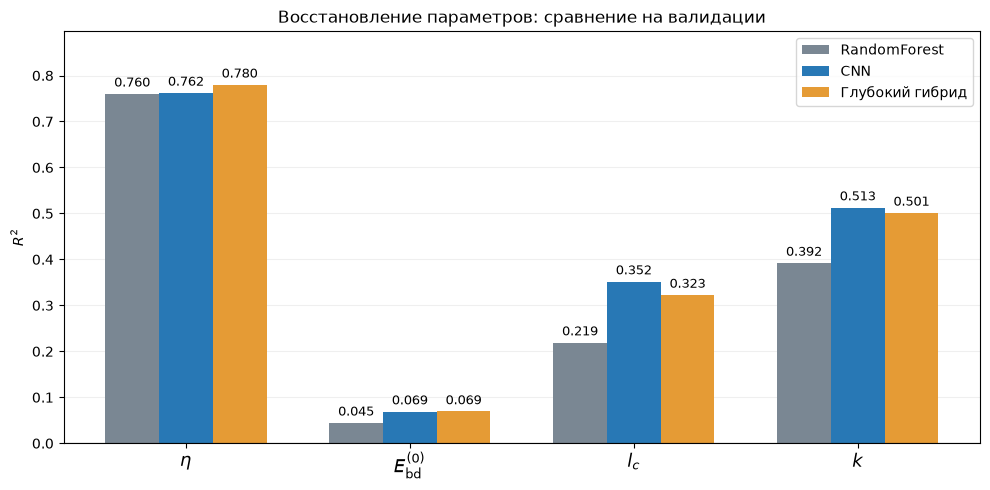

In [3]:
import matplotlib.pyplot as plt

plot_table = (
    three_model_comparison
    .set_index("parameter")
    .loc[columns]
)

parameter_labels = [
    r"$\eta$",
    r"$E_{\mathrm{bd}}^{(0)}$",
    r"$l_c$",
    r"$k$",
]

model_styles = [
    ("RF", "RandomForest", "#7A8793"),
    ("CNN", "CNN", "#2878B5"),
    ("Hybrid", "Глубокий гибрид", "#E59B35"),
]

x = np.arange(len(columns))
width = 0.24

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(10, 5), facecolor="white")

    for index, (suffix, label, color) in enumerate(model_styles):
        bars = ax.bar(
            x + (index - 1) * width,
            plot_table[f"R2_{suffix}"].to_numpy(),
            width=width,
            label=label,
            color=color,
        )

        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(parameter_labels, fontsize=13)
    ax.set_ylabel(r"$R^2$")
    ax.set_title("Восстановление параметров: сравнение на валидации")
    ax.axhline(0, color="#444444", linewidth=0.8)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.margins(y=0.15)
    ax.legend()

    fig.tight_layout()
    fig.savefig(
        HYBRID_DIR / "three_models_validation_r2.png",
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

In [4]:
N_BOOTSTRAP = 5000
rng = np.random.default_rng(42)

assert hybrid_table["point_id"].notna().all()

error_differences = pd.DataFrame({
    column: (
        np.abs(
            cnn_aligned[f"predicted_{column}"].to_numpy()
            - hybrid_table[f"true_{column}"].to_numpy()
        )
        - np.abs(
            hybrid_table[f"predicted_{column}"].to_numpy()
            - hybrid_table[f"true_{column}"].to_numpy()
        )
    )
    for column in columns
})

error_differences["point_id"] = (
    hybrid_table["point_id"].to_numpy()
)

grouped = error_differences.groupby("point_id", sort=False)

group_sums = grouped[columns].sum().to_numpy()
group_sizes = grouped.size().to_numpy()

number_of_groups = len(group_sizes)
assert number_of_groups >= 2

bootstrap_differences = np.empty(
    (N_BOOTSTRAP, len(columns))
)

for iteration in range(N_BOOTSTRAP):
    sampled_groups = rng.integers(
        low=0,
        high=number_of_groups,
        size=number_of_groups,
    )

    bootstrap_differences[iteration] = (
        group_sums[sampled_groups].sum(axis=0)
        / group_sizes[sampled_groups].sum()
    )

observed_difference = (
    error_differences[columns].mean().to_numpy()
)

lower, upper = np.quantile(
    bootstrap_differences,
    [0.025, 0.975],
    axis=0,
)

bootstrap_comparison = pd.DataFrame({
    "parameter": columns,
    "MAE_CNN_minus_Hybrid": observed_difference,
    "CI95_low": lower,
    "CI95_high": upper,
    "conclusion": np.where(
        lower > 0,
        "В пользу гибрида",
        np.where(
            upper < 0,
            "В пользу CNN",
            "Интервал включает ноль",
        ),
    ),
})

print("Групп point_id:", number_of_groups)
print("Бутстрэп-выборок:", N_BOOTSTRAP)
display(bootstrap_comparison.round(5))

bootstrap_comparison.to_csv(
    HYBRID_DIR / "cnn_vs_hybrid_group_bootstrap.csv",
    index=False,
)

Групп point_id: 1192
Бутстрэп-выборок: 5000


,parameter,MAE_CNN_minus_Hybrid,CI95_low,CI95_high,conclusion
0,eta,0.01609,0.00759,0.02482,В пользу гибрида
1,mean_breakdown_field,-0.00040,-0.00242,0.00155,Интервал включает ноль
2,correlation_length,-0.09873,-0.17214,-0.03013,В пользу CNN
3,weibull_shape,-0.03413,-0.08513,0.01570,Интервал включает ноль


## Сравнение CNN и глубокого гибрида: групповой бутстрэп

Для каждого параметра рассматривается разница:

$$
\Delta = \mathrm{MAE}_{CNN} - \mathrm{MAE}_{Hybrid}.
$$

- **Δ > 0:** гибрид имеет меньшую ошибку.
- **Δ < 0:** CNN имеет меньшую ошибку.
- **Δ = 0:** ошибки моделей одинаковы.

### Как выполнен расчёт

Сравнение проводится на **1706 одинаковых примерах**, сопоставленных
по `run_id`. Для каждого примера вычисляется разница абсолютных ошибок
CNN и гибрида.

Примеры объединяются в **1192 группы по `point_id`**. Каждая группа
содержит симуляции для одной комбинации физических параметров.

В каждом из **5000 повторов** случайно выбираются 1192 группы
**с возвращением**: одни группы могут попасть несколько раз,
другие — не попасть. Все примеры выбранной группы включаются вместе.

На полученной выборке рассчитывается разница MAE. Она вычисляется
по всем вошедшим примерам с учётом размеров групп.

Бутстрэп является **парным**: обе модели в каждом повторе оцениваются
на одних и тех же примерах. Веса моделей остаются фиксированными.

Границы приблизительного **95% доверительного интервала** определяются
как квантили 2.5% и 97.5% полученных разниц MAE.

### Результаты на валидации

| Параметр | Δ MAE: CNN − гибрид | 95% доверительный интервал | Интерпретация |
|---|---:|---:|---|
| η | +0.01609 | [+0.00759; +0.02482] | В пользу гибрида |
| E_bd^(0) | −0.00040 | [−0.00242; +0.00155] | Интервал включает ноль |
| l_c | −0.09873 | [−0.17214; −0.03013] | В пользу CNN |
| k | −0.03413 | [−0.08513; +0.01570] | Интервал включает ноль |

Для **η** интервал полностью положителен: преимущество гибрида
устойчиво к пересэмплированию групп.

Для **l_c** интервал полностью отрицателен: преимущество прежней CNN
устойчиво к пересэмплированию групп.

Для **E_bd^(0)** и **k** интервалы включают ноль:
убедительного различия данным расчётом не выявлено.
Это не доказывает равенство моделей.

### Ограничения интерпретации

Расчёт оценивает неопределённость из-за состава валидации
для двух фиксированных моделей при пересэмплировании групп `point_id`.

Он не учитывает разброс результатов при повторном обучении.
Кроме того, лучшие эпохи выбирались по этой же валидации,
поэтому сравнение носит исследовательский характер.


In [22]:
import joblib
checkpoint_file = HYBRID_DIR / "best_deep_hybrid.pt"
preprocessor_file = HYBRID_DIR / "feature_preprocessor.joblib"

assert checkpoint_file.is_file(), checkpoint_file
assert preprocessor_file.is_file(), preprocessor_file

test_checkpoint = torch.load(
    checkpoint_file,
    map_location="cpu",
    weights_only=False,
)

saved_preprocessor = joblib.load(preprocessor_file)

FEATURE_COLUMNS = list(test_checkpoint["feature_columns"])
TARGET_COLUMNS = list(test_checkpoint["target_columns"])

DATA_DIR = PROJECT_ROOT / "data" / "ml_dataset"

dataset = pd.read_csv(
    DATA_DIR / "dataset_inverse.csv",
    dtype={
        "run_id": str,
        "disorder_seed": "uint64",
        "random_seed": "uint64",
    },
)

test_data = (
    dataset.loc[dataset["split"] == "test"]
    .reset_index(drop=True)
    .copy()
)

development_data = dataset.loc[dataset["split"] == "train"]

assert not test_data.empty
assert test_data["run_id"].notna().all()
assert test_data["run_id"].is_unique
assert test_data["point_id"].notna().all()

assert set(test_data["point_id"]).isdisjoint(
    set(development_data["point_id"])
), "Есть общие point_id между test и исходным train"

test_features = test_data[FEATURE_COLUMNS].replace(
    [np.inf, -np.inf],
    np.nan,
)

saved_imputer = saved_preprocessor.named_steps["imputer"]
saved_scaler = saved_preprocessor.named_steps["scaler"]

assert saved_imputer.strategy == "median"
assert not saved_imputer.add_indicator
assert saved_scaler.with_mean and saved_scaler.with_std

feature_medians = np.asarray(
    saved_imputer.statistics_, dtype=np.float64
)
feature_means = np.asarray(
    saved_scaler.mean_, dtype=np.float64
)
feature_scales = np.asarray(
    saved_scaler.scale_, dtype=np.float64
)

expected_shape = (len(FEATURE_COLUMNS),)

for values in [feature_medians, feature_means, feature_scales]:
    assert values.shape == expected_shape
    assert np.isfinite(values).all()

assert (feature_scales > 0).all()

if hasattr(saved_imputer, "feature_names_in_"):
    assert list(saved_imputer.feature_names_in_) == FEATURE_COLUMNS

test_values = test_features.to_numpy(dtype=np.float64)

test_values = np.where(
    np.isnan(test_values),
    feature_medians,
    test_values,
)

X_test = (
    (test_values - feature_means) / feature_scales
).astype(np.float32)

assert np.isfinite(X_test).all()

saved_target_mean = pd.Series(
    test_checkpoint["target_mean"]
).reindex(TARGET_COLUMNS)

saved_target_std = pd.Series(
    test_checkpoint["target_std"]
).reindex(TARGET_COLUMNS)

assert saved_target_mean.notna().all()
assert saved_target_std.notna().all()
assert (saved_target_std > 0).all()

y_test = (
    (test_data[TARGET_COLUMNS] - saved_target_mean)
    / saved_target_std
).to_numpy(dtype=np.float32)

assert np.isfinite(X_test).all()
assert np.isfinite(y_test).all()

test_dataset = DBMHybridDataset(
    frame=test_data,
    features=X_test,
    targets=y_test,
    data_dir=DATA_DIR,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

test_model = DBMDeepHybridCNN(
    **test_checkpoint["model_config"]
)

test_model.load_state_dict(
    test_checkpoint["model_state_dict"]
)
test_model.to(DEVICE)
test_model.eval()

print("Устройство:", DEVICE)
print("Лучшая эпоха:", test_checkpoint["epoch"])
print("Тестовых примеров:", len(test_dataset))
print("Признаки:", X_test.shape)
print("Цели:", y_test.shape)

Устройство: cpu
Лучшая эпоха: 15
Тестовых примеров: 1933
Признаки: (1933, 27)
Цели: (1933, 4)


/home/artur/miniconda/envs/mathprac/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/artur/miniconda/envs/mathprac/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/artur/miniconda/envs/mathprac/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 

In [23]:
from tqdm.auto import tqdm
from sklearn.metrics import mean_absolute_error, r2_score

test_model.eval()
prediction_batches = []

with torch.inference_mode():
    for masks, features, _ in tqdm(
        test_loader,
        desc="Проверка на тесте",
        unit="batch",
        colour="green",
        leave=True,
    ):
        masks = masks.to(DEVICE)
        features = features.to(DEVICE)

        predictions = test_model(masks, features)
        prediction_batches.append(predictions.cpu().numpy())

normalized_predictions = np.concatenate(
    prediction_batches,
    axis=0,
)

hybrid_test_predictions = (
    normalized_predictions
    * saved_target_std.to_numpy(dtype=np.float64)
    + saved_target_mean.to_numpy(dtype=np.float64)
)

hybrid_test_targets = test_data[TARGET_COLUMNS].to_numpy(
    dtype=np.float64,
)

assert hybrid_test_predictions.shape == hybrid_test_targets.shape
assert np.isfinite(hybrid_test_predictions).all()

metric_rows = []

for index, target in enumerate(TARGET_COLUMNS):
    actual = hybrid_test_targets[:, index]
    predicted = hybrid_test_predictions[:, index]

    metric_rows.append(
        {
            "target": target,
            "mae": mean_absolute_error(actual, predicted),
            "rmse": np.sqrt(np.mean((actual - predicted) ** 2)),
            "r2": r2_score(actual, predicted),
        }
    )

hybrid_test_metrics = pd.DataFrame(metric_rows)

metadata_columns = [
    column
    for column in [
        "run_id", "point_id", "disorder_seed", "random_seed", "status"
    ]
    if column in test_data.columns
]

hybrid_test_table = test_data[metadata_columns].copy()

for index, target in enumerate(TARGET_COLUMNS):
    hybrid_test_table[f"true_{target}"] = hybrid_test_targets[:, index]
    hybrid_test_table[f"predicted_{target}"] = (
        hybrid_test_predictions[:, index]
    )

HYBRID_DIR.mkdir(parents=True, exist_ok=True)

hybrid_test_metrics.to_csv(
    HYBRID_DIR / "test_metrics.csv",
    index=False,
)

hybrid_test_table.to_csv(
    HYBRID_DIR / "test_predictions.csv",
    index=False,
)

display(hybrid_test_metrics.round(4))

Проверка на тесте:   0%|          | 0/61 [00:00<?, ?batch/s]

,target,mae,rmse,r2
0,eta,0.2271,0.3048,0.8215
1,mean_breakdown_field,0.1344,0.1606,0.0638
2,correlation_length,3.2786,4.0579,0.1707
3,weibull_shape,2.2677,2.8288,0.4398


In [24]:
cnn_test_file = CNN_DIR / "test_predictions.csv"
assert cnn_test_file.exists(), f"Не найден файл: {cnn_test_file}"

cnn_test_table = pd.read_csv(
    cnn_test_file,
    dtype={"run_id": str},
)

for name, table in [
    ("CNN", cnn_test_table),
    ("Hybrid", hybrid_test_table),
]:
    assert table["run_id"].notna().all(), f"{name}: пустые run_id"
    assert table["run_id"].is_unique, f"{name}: повторяются run_id"

assert set(cnn_test_table["run_id"]) == set(
    hybrid_test_table["run_id"]
), "Модели проверены на разных тестовых примерах"

cnn_test_aligned = (
    cnn_test_table
    .set_index("run_id")
    .loc[hybrid_test_table["run_id"]]
    .reset_index()
)

comparison_rows = []

for target in TARGET_COLUMNS:
    actual = hybrid_test_table[f"true_{target}"].to_numpy()

    np.testing.assert_allclose(
        cnn_test_aligned[f"true_{target}"].to_numpy(),
        actual,
        rtol=1e-5,
        atol=1e-5,
        err_msg=f"Не совпадают настоящие значения: {target}",
    )

    cnn_predicted = cnn_test_aligned[
        f"predicted_{target}"
    ].to_numpy()

    hybrid_predicted = hybrid_test_table[
        f"predicted_{target}"
    ].to_numpy()

    assert np.isfinite(cnn_predicted).all()
    assert np.isfinite(hybrid_predicted).all()

    comparison_rows.append(
        {
            "target": target,
            "MAE_CNN": mean_absolute_error(actual, cnn_predicted),
            "MAE_Hybrid": mean_absolute_error(actual, hybrid_predicted),
            "RMSE_CNN": np.sqrt(np.mean((actual - cnn_predicted) ** 2)),
            "RMSE_Hybrid": np.sqrt(
                np.mean((actual - hybrid_predicted) ** 2)
            ),
            "R2_CNN": r2_score(actual, cnn_predicted),
            "R2_Hybrid": r2_score(actual, hybrid_predicted),
        }
    )

test_comparison = pd.DataFrame(comparison_rows)

test_comparison.to_csv(
    HYBRID_DIR / "cnn_vs_hybrid_test.csv",
    index=False,
)

print("Сопоставлено тестовых примеров:", len(cnn_test_aligned))
display(test_comparison.round(4))

Сопоставлено тестовых примеров: 1933


,target,MAE_CNN,MAE_Hybrid,RMSE_CNN,RMSE_Hybrid,R2_CNN,R2_Hybrid
0,eta,0.2369,0.2271,0.3144,0.3048,0.8100,0.8215
1,mean_breakdown_field,0.1326,0.1344,0.1597,0.1606,0.0741,0.0638
2,correlation_length,3.1719,3.2786,4.0073,4.0579,0.1912,0.1707
3,weibull_shape,2.2629,2.2677,2.8378,2.8288,0.4362,0.4398


In [25]:
N_TEST_BOOTSTRAPS = 5000
test_rng = np.random.default_rng(42)

assert hybrid_test_table["point_id"].notna().all()

assert np.array_equal(
    cnn_test_aligned["run_id"].to_numpy(),
    hybrid_test_table["run_id"].to_numpy(),
), "Нарушено сопоставление тестовых примеров"

test_error_differences = pd.DataFrame(
    {
        target: (
            np.abs(
                hybrid_test_table[f"true_{target}"].to_numpy()
                - cnn_test_aligned[f"predicted_{target}"].to_numpy()
            )
            - np.abs(
                hybrid_test_table[f"true_{target}"].to_numpy()
                - hybrid_test_table[f"predicted_{target}"].to_numpy()
            )
        )
        for target in TARGET_COLUMNS
    }
)

test_error_differences["point_id"] = (
    hybrid_test_table["point_id"].to_numpy()
)

test_groups = test_error_differences.groupby(
    "point_id",
    sort=False,
)

test_group_sums = (
    test_groups[TARGET_COLUMNS].sum().to_numpy(dtype=np.float64)
)

test_group_sizes = test_groups.size().to_numpy()
number_of_test_groups = len(test_group_sizes)

assert number_of_test_groups >= 2

test_bootstrap_differences = np.empty(
    (N_TEST_BOOTSTRAPS, len(TARGET_COLUMNS)),
    dtype=np.float64,
)

for iteration in tqdm(
    range(N_TEST_BOOTSTRAPS),
    desc="Бутстрэп теста",
    unit="resample",
    colour="green",
):
    sampled_groups = test_rng.integers(
        low=0,
        high=number_of_test_groups,
        size=number_of_test_groups,
    )

    test_bootstrap_differences[iteration] = (
        test_group_sums[sampled_groups].sum(axis=0)
        / test_group_sizes[sampled_groups].sum()
    )

test_ci_low, test_ci_high = np.quantile(
    test_bootstrap_differences,
    [0.025, 0.975],
    axis=0,
)

test_bootstrap_summary = pd.DataFrame(
    {
        "target": TARGET_COLUMNS,
        "MAE_CNN_minus_Hybrid": (
            test_error_differences[TARGET_COLUMNS].mean().to_numpy()
        ),
        "CI95_low": test_ci_low,
        "CI95_high": test_ci_high,
        "conclusion": np.select(
            [
                test_ci_low > 0,
                test_ci_high < 0,
            ],
            [
                "Преимущество Hybrid",
                "Преимущество CNN",
            ],
            default="Интервал включает ноль",
        ),
    }
)

test_bootstrap_summary.to_csv(
    HYBRID_DIR / "cnn_vs_hybrid_test_group_bootstrap.csv",
    index=False,
)

print("Тестовых примеров:", len(hybrid_test_table))
print("Групп point_id:", number_of_test_groups)
display(test_bootstrap_summary.round(5))

Бутстрэп теста:   0%|          | 0/5000 [00:00<?, ?resample/s]

Тестовых примеров: 1933
Групп point_id: 1401


,target,MAE_CNN_minus_Hybrid,CI95_low,CI95_high,conclusion
0,eta,0.00979,0.00201,0.01742,Преимущество Hybrid
1,mean_breakdown_field,-0.00180,-0.00364,0.00003,Интервал включает ноль
2,correlation_length,-0.10662,-0.17575,-0.03943,Преимущество CNN
3,weibull_shape,-0.00477,-0.05083,0.04105,Интервал включает ноль


## Итоги: глубокая гибридная модель

В этом ноутбуке реализована модель, объединяющая бинарную маску
канала пробоя и 27 морфологических признаков.

Свёрточный энкодер содержит четыре уровня с 16, 32, 64 и 128
каналами, по два остаточных блока на каждом уровне.
Представление изображения объединяется с представлением
морфологических признаков для восстановления четырёх параметров.
Всего модель содержит 1 793 764 обучаемых параметра.

Лучшие веса выбраны по validation loss на 15-й эпохе.
Финальная проверка выполнена на 1933 тестовых примерах.
Предсказания прежней CNN и гибридной модели сопоставлены по `run_id`;
проверено совпадение настоящих значений параметров.

### Сравнение на тестовой выборке

| Параметр | MAE CNN | MAE Hybrid | R² CNN | R² Hybrid |
|---|---:|---:|---:|---:|
| η | 0.2369 | **0.2271** | 0.8100 | **0.8215** |
| E_bd^(0) | **0.1326** | 0.1344 | **0.0741** | 0.0638 |
| l_c | **3.1719** | 3.2786 | **0.1912** | 0.1707 |
| k | **2.2629** | 2.2677 | 0.4362 | **0.4398** |

Гибридная модель уменьшила MAE для η примерно на 4.1%.
Для l_c ошибка увеличилась примерно на 3.4%.
Для E_bd^(0) и k различия небольшие.

### Парный групповой бутстрэп

Для оценки неопределённости сравнения выполнено 5000
бутстрэп-повторов по 1401 группе `point_id`.

Группы выбирались с возвращением вместе со всеми входящими
в них изображениями. В каждом повторе обе модели оценивались
на одной и той же выборке. Разность MAE рассчитывалась
с учётом числа изображений в выбранных группах.

Использована разность **ΔMAE = MAE_CNN − MAE_Hybrid**:

- положительное значение означает преимущество Hybrid;
- отрицательное — преимущество CNN;
- интервал, включающий ноль, не позволяет уверенно установить
  направление различия этим методом.

| Параметр | ΔMAE | 95% бутстрэп-интервал | Интерпретация |
|---|---:|---:|---|
| η | +0.00979 | [+0.00201; +0.01742] | Поддерживает преимущество Hybrid |
| E_bd^(0) | −0.00180 | [−0.00364; +0.00003] | Интервал включает ноль |
| l_c | −0.10662 | [−0.17575; −0.03943] | Поддерживает преимущество CNN |
| k | −0.00477 | [−0.05083; +0.04105] | Интервал включает ноль |

Интервалы рассчитаны отдельно для каждого параметра, без поправки
на множественные сравнения. Они характеризуют неопределённость
из-за состава тестовых групп для двух фиксированных обученных
моделей. Вариативность между запусками обучения не учитывается.
Включение нуля в интервал не доказывает равенство моделей.

### Вывод

**В данном эксперименте увеличение глубины вместе с добавлением
морфологических признаков не принесло общего улучшения.**

Небольшое преимущество гибрида по η и преимущество прежней CNN
по l_c согласуются с результатами на валидации.
Для E_bd^(0) и k убедительного различия MAE не выявлено.

Низкий R² для E_bd^(0) сохраняется у обеих моделей.
Это указывает на трудности восстановления параметра в текущей
постановке, но не доказывает его принципиальную неидентифицируемость.

Глубина и морфологическая ветвь изменены одновременно,
поэтому их отдельные вклады этим экспериментом не установлены.

Прежняя CNN сохраняется как основная модель для дальнейшего
сравнения. Гибридная модель фиксируется как завершённый эксперимент
с локальным улучшением по η. Обучение, проверка и сравнение
глубокой модели завершены; метрики, предсказания и результаты
бутстрэпа сохранены.